# Árboles de decisión y métodos de ensamble

Los árboles de decisión dividen el espacio de los predictores en regiones rectangulares mediante preguntas sucesivas y asignan a cada región una clase o un valor. Por sí solos son interpretables pero inestables; combinados en ensambles, como los bosques aleatorios y el boosting, están entre los modelos más precisos para datos tabulares y son los más usados en los estudios de susceptibilidad {cite}`james2021,merghadi2020`.

## Árboles de decisión

Un árbol tiene un nodo raíz, nodos internos, que hacen una prueba sobre un atributo ("¿pendiente > 28°?"), ramas, que son los resultados de la prueba, y hojas, que asignan la clase. El camino de la raíz a una hoja es una regla de clasificación. El árbol se construye de arriba hacia abajo: en cada nodo se elige la variable y el punto de corte que producen los nodos hijos más puros, medidos con la impureza de Gini, $1 - \sum_k p_k^2$, o con la entropía, $-\sum_k p_k \log p_k$. La división se detiene cuando todas las muestras de un nodo son de la misma clase, cuando no quedan atributos o cuando se cumple un criterio de parada: profundidad máxima, número mínimo de muestras por nodo o por hoja.

Los árboles tienen ventajas prácticas: se construyen rápido, son interpretables si son pequeños, manejan variables numéricas y categóricas, son invariantes a transformaciones monótonas de los predictores (no hace falta escalar) y poco sensibles a los atípicos en los predictores, y hacen selección de variables implícita. Su gran problema es la varianza: un pequeño cambio en los datos puede producir un árbol muy distinto.

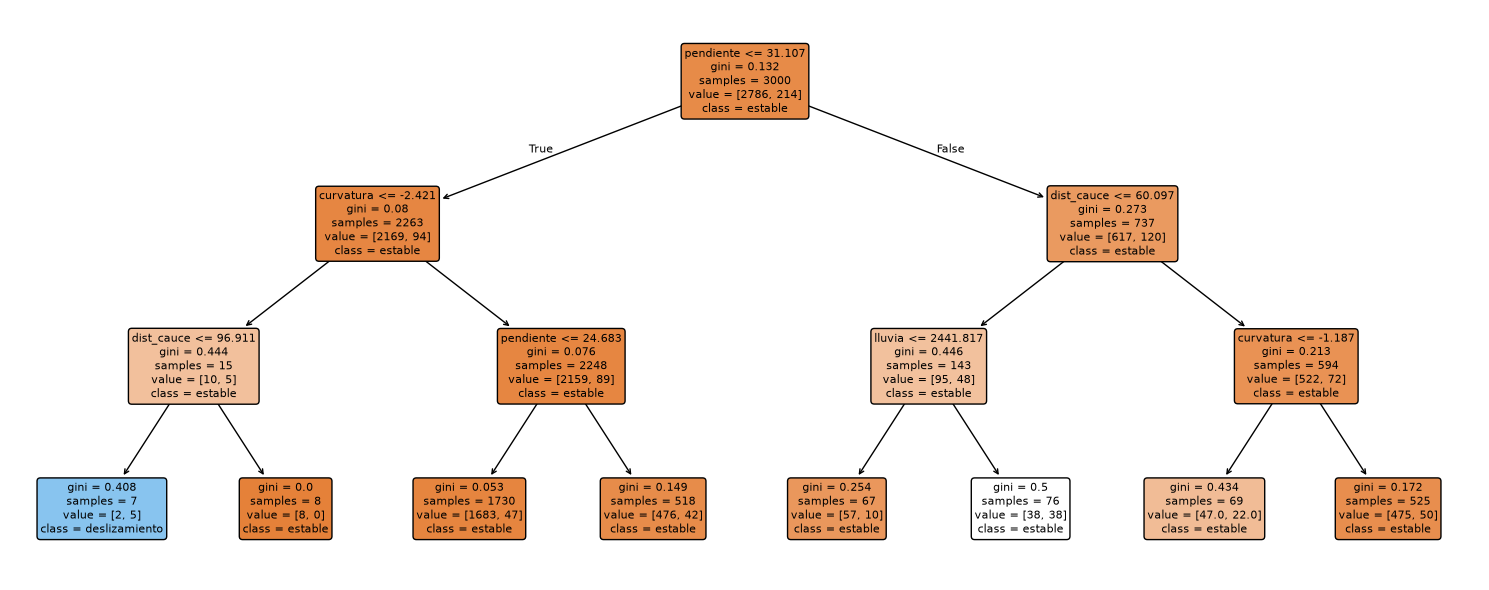

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import cross_val_score, StratifiedKFold
plt.rcParams['figure.dpi'] = 100
rng = np.random.default_rng(12)

def inventario(n=3000, semilla=12):
    r = np.random.default_rng(semilla)
    pend = r.gamma(4, 6, n); dist = r.exponential(250, n); lluv = r.normal(2500, 500, n); curv = r.normal(0, 1, n)
    # relación no lineal con un umbral de pendiente y una interacción pendiente-lluvia
    eta = -3 + 2.2 / (1 + np.exp(-(pend - 28) / 3)) - 0.004 * dist + 0.0015 * (lluv - 2500) * (pend > 20) - 0.6 * curv
    y = (r.random(n) < 1 / (1 + np.exp(-eta))).astype(int)
    return np.column_stack([pend, dist, lluv, curv]), y

X, y = inventario()
nombres = ['pendiente', 'dist_cauce', 'lluvia', 'curvatura']
arbol = DecisionTreeClassifier(max_depth=3, random_state=0).fit(X, y)
fig, ax = plt.subplots(figsize=(15, 6))
plot_tree(arbol, feature_names=nombres, class_names=['estable', 'deslizamiento'], filled=True, rounded=True, fontsize=8, ax=ax)
plt.tight_layout(); plt.show()

El árbol pone en la raíz un umbral de pendiente cercano al de la simulación (la probabilidad crece bruscamente alrededor de 28°) y luego divide por la lluvia, que solo actúa en pendientes fuertes. Para ver su inestabilidad basta entrenarlo con dos muestras bootstrap distintas y comparar las reglas.

In [2]:
for s in range(3):
    i = np.random.default_rng(s).integers(0, len(y), len(y))
    a = DecisionTreeClassifier(max_depth=2, random_state=0).fit(X[i], y[i])
    t = a.tree_
    print(f'muestra {s}: raíz "{nombres[t.feature[0]]} <= {t.threshold[0]:.1f}", '
          f'nodo izquierdo "{nombres[t.feature[1]]} <= {t.threshold[1]:.1f}", nodo derecho "{nombres[t.feature[4]]} <= {t.threshold[4]:.1f}"')

muestra 0: raíz "pendiente <= 31.1", nodo izquierdo "lluvia <= 3746.2", nodo derecho "lluvia <= 2871.1"
muestra 1: raíz "pendiente <= 32.9", nodo izquierdo "lluvia <= 3746.2", nodo derecho "dist_cauce <= 59.3"
muestra 2: raíz "pendiente <= 41.8", nodo izquierdo "lluvia <= 3824.3", nodo derecho "lluvia <= 2551.9"


## Ensambles: bagging y bosques aleatorios

Un método de ensamble combina las predicciones de muchos modelos base para obtener uno más robusto y con mejor capacidad de generalización. El bagging (bootstrap aggregating) entrena muchos árboles profundos, cada uno con una muestra bootstrap de los datos, y promedia sus predicciones (o vota). Los árboles profundos tienen sesgo bajo y varianza alta, y promediar muchos reduce la varianza sin cambiar el sesgo. El bosque aleatorio {cite}`breiman2001` agrega un truco: en cada división solo se considera un subconjunto aleatorio de las variables (típicamente $\sqrt{p}$), lo que hace los árboles menos correlacionados entre sí y potencia la reducción de varianza. Como cada árbol deja fuera cerca de un tercio de los datos, esos datos fuera de la bolsa (out-of-bag) dan una estimación del error sin necesidad de un conjunto de validación.

La celda siguiente repite un experimento clásico: ajusta un árbol y un bosque aleatorio a muchas muestras pequeñas de una relación conocida y compara el ancho de la nube de predicciones, que refleja la varianza.

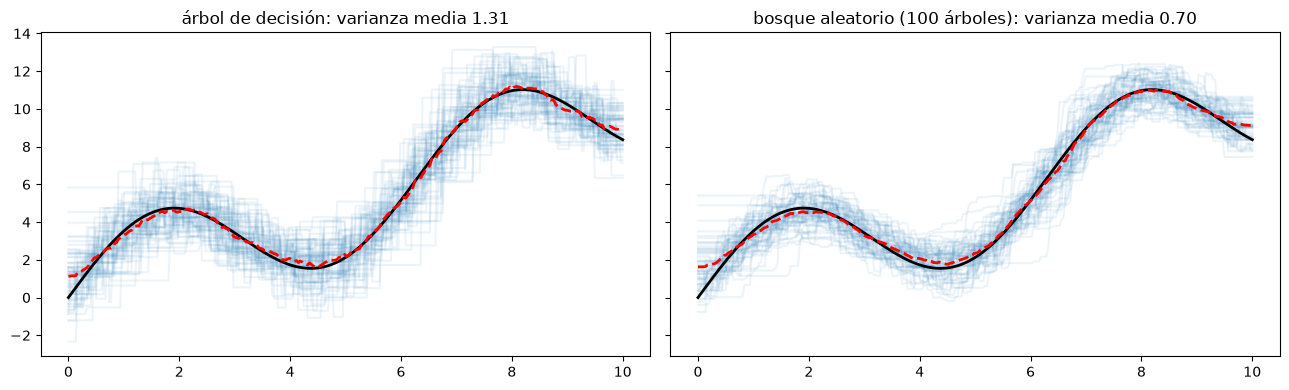

In [3]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
f = lambda x: 3 * np.sin(x) + x
xx = np.linspace(0, 10, 300)[:, None]
fig, ax = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for a, (nom, mod) in zip(ax, [('árbol de decisión', DecisionTreeRegressor()), ('bosque aleatorio (100 árboles)', RandomForestRegressor(100, random_state=0, n_jobs=-1))]):
    P = []
    for s in range(60):
        r = np.random.default_rng(s); x = r.uniform(0, 10, (30, 1)); yy = f(x[:, 0]) + r.normal(0, 1, 30)
        P.append(mod.fit(x, yy).predict(xx)); a.plot(xx, P[-1], color='tab:blue', alpha=0.08)
    P = np.array(P); a.plot(xx, f(xx), 'k', lw=2); a.plot(xx, P.mean(0), 'r--', lw=2)
    a.set_title(f'{nom}: varianza media {P.var(0).mean():.2f}')
plt.tight_layout(); plt.show()

## Boosting

El boosting construye los modelos de forma secuencial: cada modelo nuevo se concentra en los errores de los anteriores. Usa modelos base simples, de sesgo alto y varianza baja, como árboles de una o pocas divisiones (tocones), y al sumarlos reduce el sesgo del conjunto. AdaBoost aumenta en cada iteración el peso de las observaciones mal clasificadas y combina los modelos con pesos proporcionales a $\log(\text{aciertos}/\text{errores})$. El boosting de gradiente {cite}`friedman2001` generaliza la idea: cada árbol nuevo se ajusta al gradiente negativo de la función de pérdida (en regresión cuadrática, a los residuos del modelo actual), y su contribución se multiplica por una tasa de aprendizaje pequeña. Implementaciones como XGBoost, LightGBM o CatBoost, y `HistGradientBoosting` de `scikit-learn`, son el estado del arte en datos tabulares. Sus hiperparámetros principales, la tasa de aprendizaje, el número de árboles y su profundidad, interactúan y deben ajustarse juntos (capítulo {doc}`09_Optimizacion`); el boosting puede sobreajustar si se agregan demasiados árboles, por lo que se usa parada temprana.

árbol (profundidad 4)    AUC en validación cruzada 0.714


bosque aleatorio         AUC en validación cruzada 0.773


AdaBoost (tocones)       AUC en validación cruzada 0.787


boosting de gradiente    AUC en validación cruzada 0.787


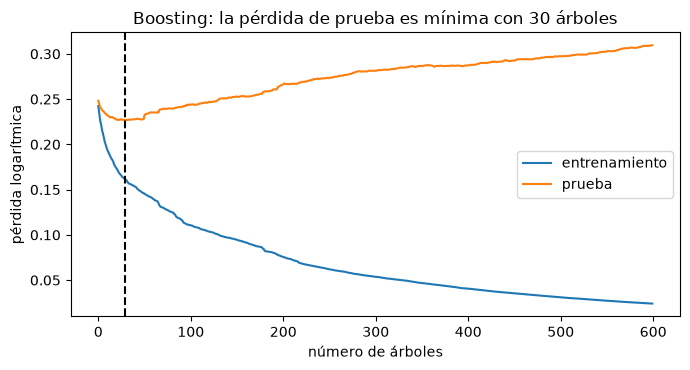

In [4]:
cv = StratifiedKFold(5, shuffle=True, random_state=0)
modelos = {'árbol (profundidad 4)': DecisionTreeClassifier(max_depth=4, random_state=0),
           'bosque aleatorio': RandomForestClassifier(300, min_samples_leaf=3, random_state=0, n_jobs=-1),
           'AdaBoost (tocones)': AdaBoostClassifier(n_estimators=300, random_state=0),
           'boosting de gradiente': GradientBoostingClassifier(n_estimators=300, learning_rate=0.05, max_depth=3, random_state=0)}
for nom, m in modelos.items():
    print(f'{nom:24s} AUC en validación cruzada {cross_val_score(m, X, y, cv=cv, scoring="roc_auc").mean():.3f}')

gb = GradientBoostingClassifier(n_estimators=600, learning_rate=0.1, max_depth=3, subsample=0.8, random_state=0)
from sklearn.model_selection import train_test_split
from sklearn.metrics import log_loss
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)
gb.fit(X_tr, y_tr)
perd_tr = [log_loss(y_tr, p[:, 1]) for p in gb.staged_predict_proba(X_tr)]
perd_te = [log_loss(y_te, p[:, 1]) for p in gb.staged_predict_proba(X_te)]
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(perd_tr, label='entrenamiento'); ax.plot(perd_te, label='prueba'); ax.axvline(np.argmin(perd_te), color='k', ls='--')
ax.set_xlabel('número de árboles'); ax.set_ylabel('pérdida logarítmica'); ax.legend()
ax.set_title(f'Boosting: la pérdida de prueba es mínima con {np.argmin(perd_te) + 1} árboles'); plt.tight_layout(); plt.show()

## Importancia de las variables

Los ensambles de árboles entregan una importancia de cada variable, la reducción total de impureza que producen sus divisiones, promediada en todos los árboles. Es útil pero sesgada a favor de las variables continuas o con muchas categorías. La importancia por permutación, que mide cuánto empeora el modelo al desordenar al azar los valores de una variable en datos de validación, es más confiable; se trata en el capítulo {doc}`17_Interpretabilidad`.

In [5]:
rf = modelos['bosque aleatorio'].fit(X_tr, y_tr)
for nm, imp in sorted(zip(nombres, rf.feature_importances_), key=lambda t: -t[1]):
    print(f'{nm:12s} {imp:.3f}')

pendiente    0.284
dist_cauce   0.257
lluvia       0.237
curvatura    0.222


## Para profundizar

El capítulo 8 de {cite}`james2021` presenta los árboles, el bagging, los bosques aleatorios y el boosting, y los capítulos 10, 15 y 16 de {cite}`hastie2009` los tratan en profundidad. {cite:t}`merghadi2020` comparan estos métodos en estudios de susceptibilidad por deslizamientos. El notebook 20 del curso aplica los ensambles con búsqueda de hiperparámetros.